In [2]:
import sqlite3
import pandas as pd
conn = sqlite3.connect("experiments.db")
df = pd.read_sql("SELECT * FROM model_results", conn)
df

,model_name,brier_score,log_loss,roc_auc,pr_auc
0,approach_01_LogisticRegression,0.217228,0.618828,0.678131,0.181430
1,approach_01_DecisionTree,0.190580,1.087462,0.615079,0.075897
2,approach_01_xgboost,0.039254,0.158755,0.761905,0.102847
3,approach_02_LogisticRegression,0.222450,0.628191,0.604217,0.157885
4,approach_02_DecisionTree,0.199951,1.440153,0.470073,0.047279
5,approach_02_xgboost,0.040897,0.175908,0.623549,0.087494
6,approach_03_LogisticRegression,0.217019,0.611537,0.714739,0.364086
7,approach_03_DecisionTree,0.193438,1.121129,0.565185,0.145532
8,approach_03_xgboost,0.047486,0.199825,0.626894,0.159108
9,approach_10_LSTM,0.071673,0.508212,0.412854,0.040124


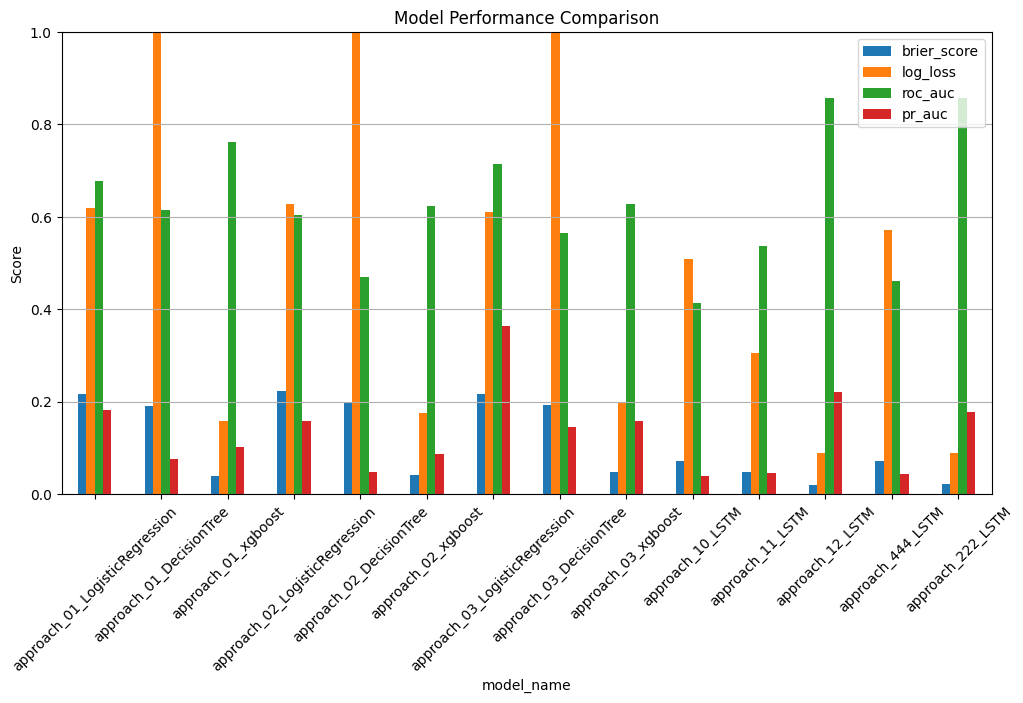

In [3]:
import matplotlib.pyplot as plt

metrics_to_plot = ["brier_score", "log_loss", "roc_auc", "pr_auc"]

df_plot = df.set_index("model_name")[metrics_to_plot]

df_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()


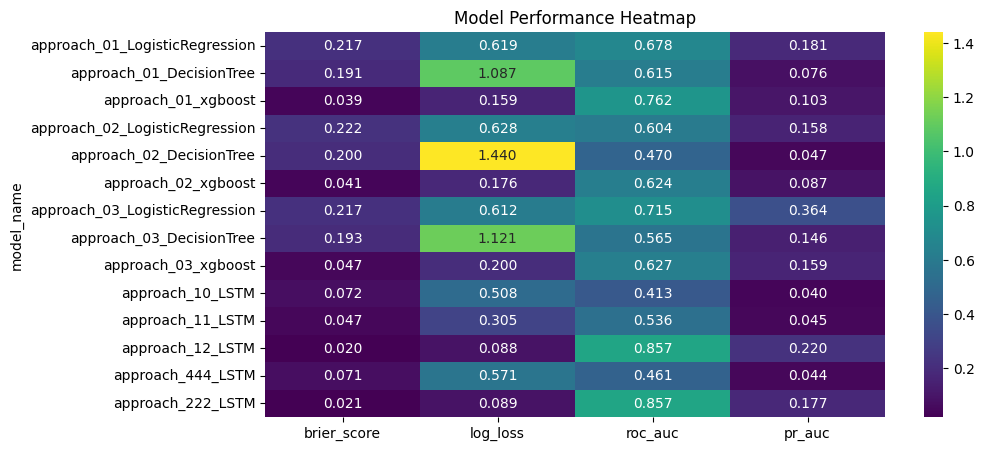

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.heatmap(
    df.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance Heatmap")
plt.show()


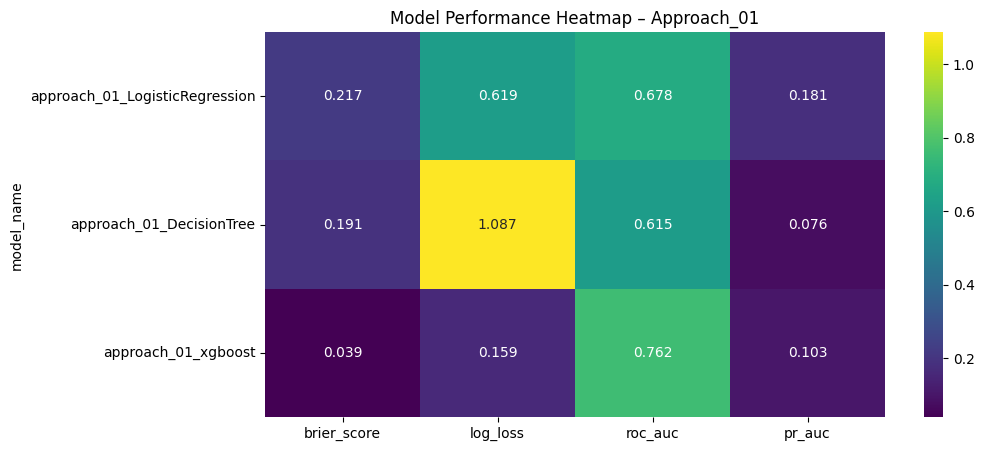

In [5]:
# Modelle filtern, deren Name mit "Approach_01" beginnt
df_filtered = df[df["model_name"].str.startswith("approach_01")]

plt.figure(figsize=(10, 5))
sns.heatmap(
    df_filtered.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance Heatmap – Approach_01")
plt.show()


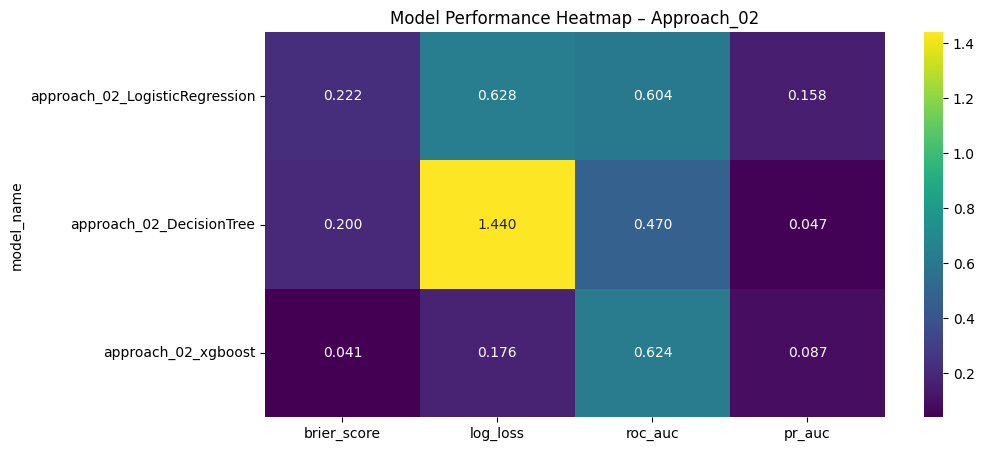

In [6]:
# Modelle filtern, deren Name mit "Approach_02" beginnt
df_filtered = df[df["model_name"].str.startswith("approach_02")]

plt.figure(figsize=(10, 5))
sns.heatmap(
    df_filtered.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance Heatmap – Approach_02")
plt.show()

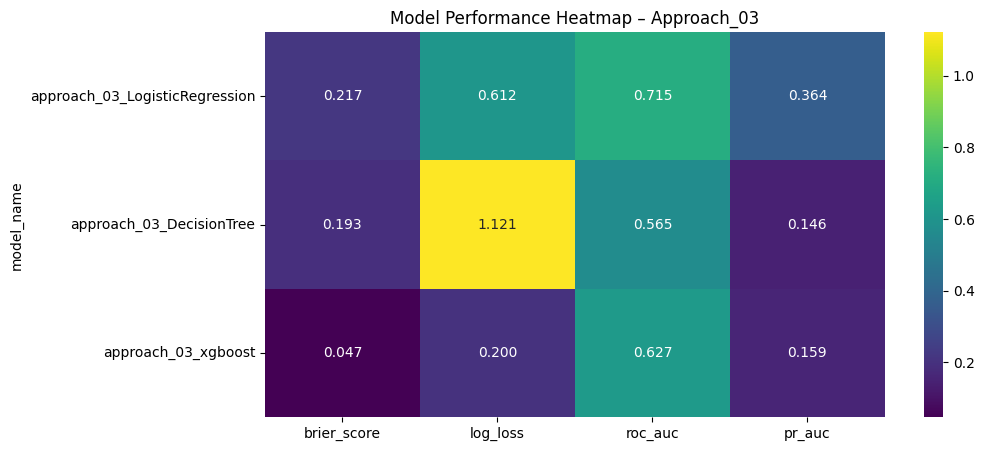

In [7]:
# Modelle filtern, deren Name mit "Approach_03" beginnt
df_filtered = df[df["model_name"].str.startswith("approach_03")]

plt.figure(figsize=(10, 5))
sns.heatmap(
    df_filtered.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance Heatmap – Approach_03")
plt.show()

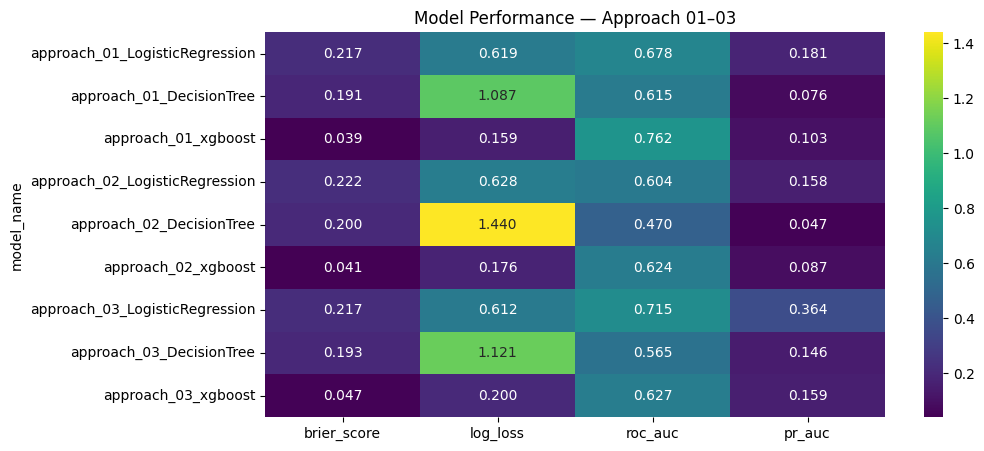

In [8]:
prefixes = ("approach_01", "approach_02", "approach_03")

df_filtered = df[df["model_name"].str.startswith(prefixes)]

plt.figure(figsize=(10, 5))
sns.heatmap(
    df_filtered.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance — Approach 01–03")
plt.show()

### LSTMs

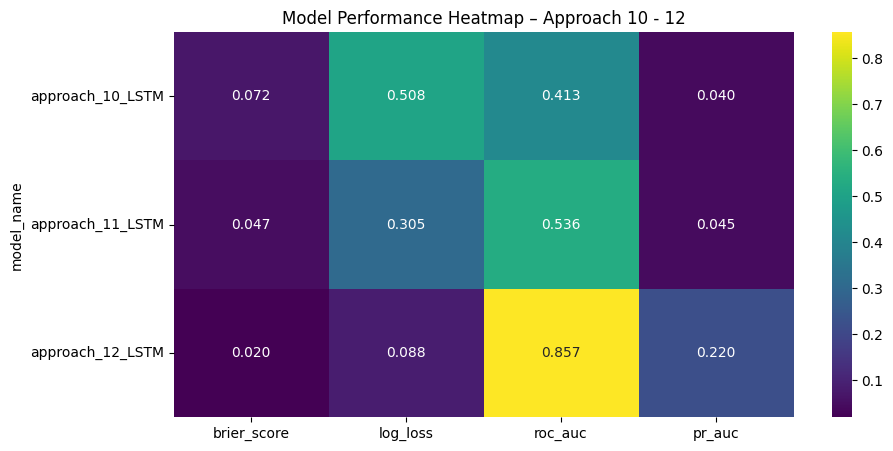

In [9]:
prefixes = ("approach_10", "approach_11", "approach_12")

df_filtered = df[df["model_name"].str.startswith(prefixes)]

plt.figure(figsize=(10, 5))
sns.heatmap(
    df_filtered.set_index("model_name")[metrics_to_plot],
    annot=True, cmap="viridis", fmt=".3f"
)
plt.title("Model Performance Heatmap – Approach 10 - 12")
plt.show()

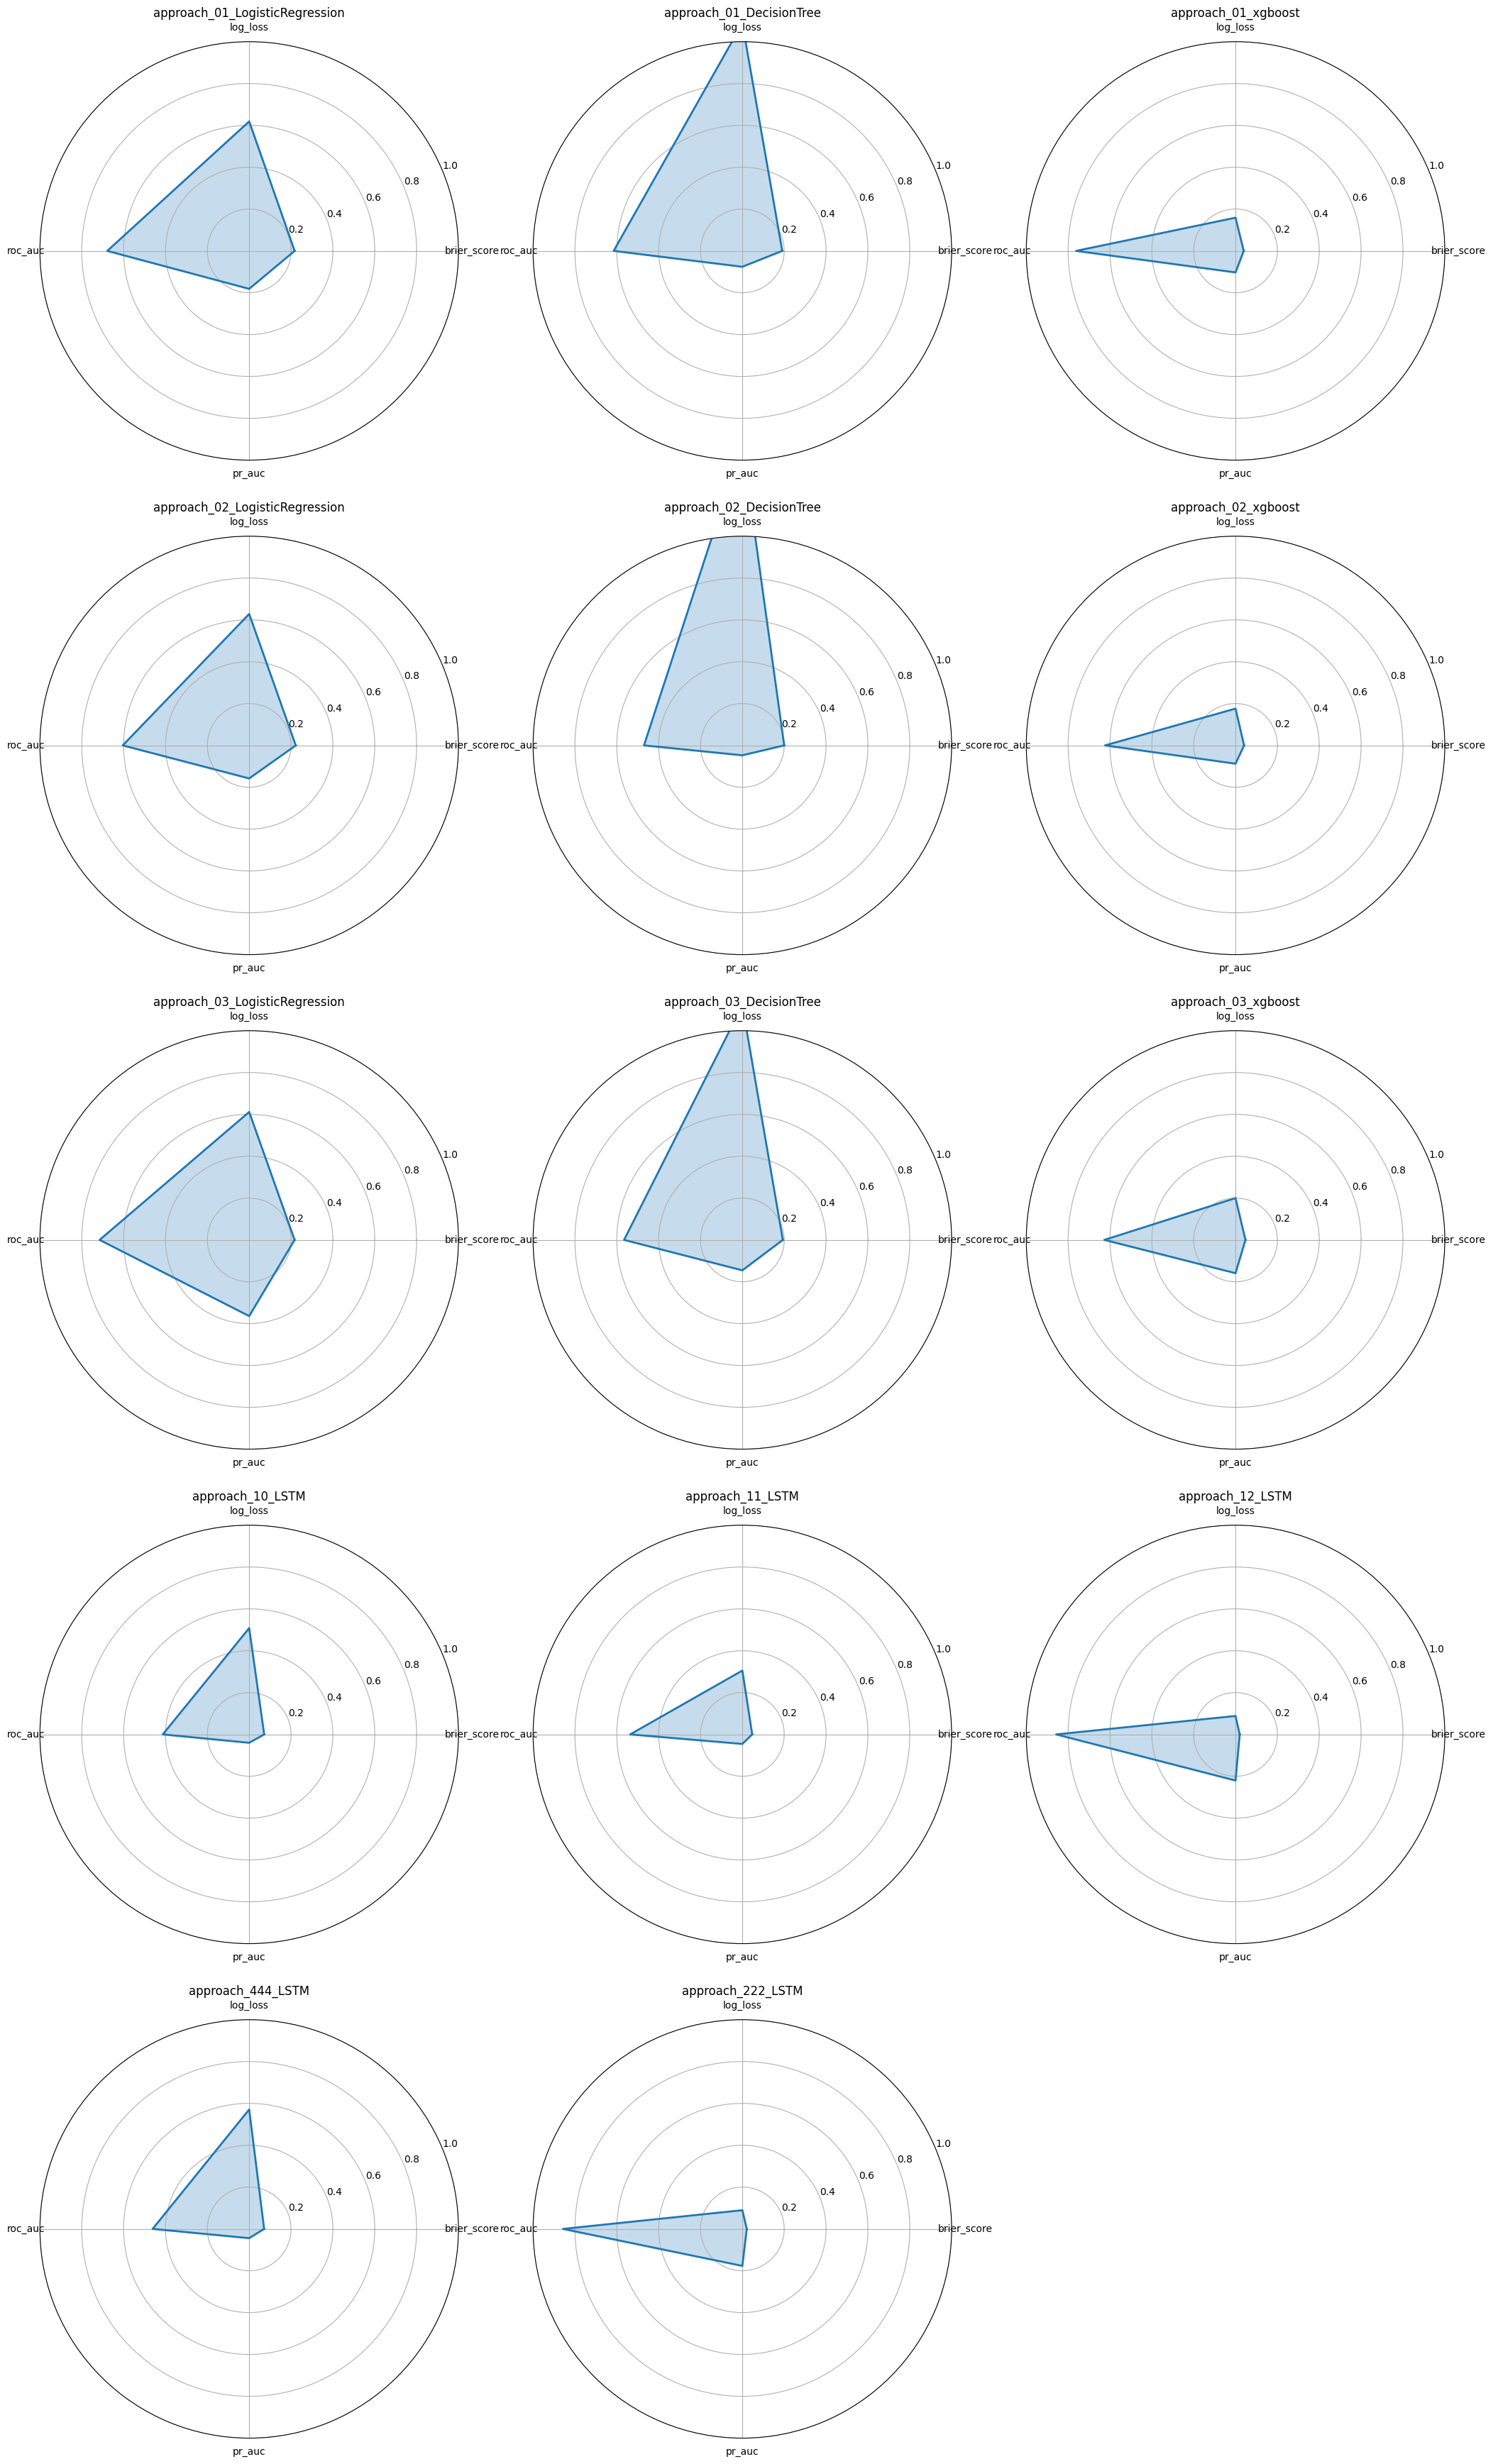

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def radar_chart_ax(ax, model_name):
    values = df.loc[df["model_name"] == model_name, metrics_to_plot].iloc[0].values
    labels = metrics_to_plot

    # Radar-Setup
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    values = np.concatenate((values, [values[0]]))
    angles = np.concatenate((angles, [angles[0]]))

    # Plot
    ax.plot(angles, values, linewidth=2)
    ax.fill(angles, values, alpha=0.25)
    ax.set_ylim(0, 1)
    ax.set_thetagrids(np.degrees(angles[:-1]), labels)
    ax.set_title(model_name)


# -------- Grid erstellen ----------
model_names = df["model_name"].unique()
n_models = len(model_names)

cols = 3
rows = int(np.ceil(n_models / cols))

fig = plt.figure(figsize=(cols * 7, rows * 7))

for i, model_name in enumerate(model_names, start=1):
    ax = fig.add_subplot(rows, cols, i, polar=True)
    radar_chart_ax(ax, model_name)

plt.tight_layout()
plt.show()
